In [1]:
%pip -q install gradio reportlab scikit-learn pillow


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 21.8 MB/s eta 0:00:00


In [2]:
import os, zipfile, random, html
from pathlib import Path
from io import BytesIO
from datetime import datetime

import numpy as np
import pandas as pd
import tensorflow as tf
import gradio as gr
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageStat, ImageFilter
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support
from reportlab.lib.pagesizes import letter
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Image as PDFImage, Table, TableStyle
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import inch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow:", tf.__version__)
print("Gradio:", gr.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
Gradio: 6.29.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
DATA_DIR = Path("/content/plantvillage_data")
EXTRACT_DIR = DATA_DIR / "PlantVillage-Dataset-master"
ZIP_PATH = DATA_DIR / "plantvillage.zip"
DATA_DIR.mkdir(parents=True, exist_ok=True)

if not EXTRACT_DIR.exists():
    import urllib.request
    url = "https://github.com/spMohanty/PlantVillage-Dataset/archive/refs/heads/master.zip"
    print("Downloading PlantVillage dataset...")
    urllib.request.urlretrieve(url, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH) as zf:
        zf.extractall(DATA_DIR)
else:
    print("Using previously extracted dataset.")

extensions = {".jpg", ".jpeg", ".png", ".bmp"}
candidates = [EXTRACT_DIR / "raw" / "color", EXTRACT_DIR / "color", EXTRACT_DIR / "PlantVillage", EXTRACT_DIR]
DATASET_ROOT = None
for root in candidates:
    if root.exists():
        dirs = [p for p in root.iterdir() if p.is_dir() and p.name.lower() not in {"data_distribution_for_svm", ".git"}]
        count = sum(1 for d in dirs for f in d.rglob("*") if f.suffix.lower() in extensions)
        if len(dirs) >= 10 and count >= 1000:
            DATASET_ROOT = root
            break
if DATASET_ROOT is None:
    raise FileNotFoundError("Could not locate the PlantVillage class folders in the extracted archive.")

items = []
for folder in sorted(DATASET_ROOT.iterdir()):
    if folder.is_dir() and folder.name.lower() not in {"data_distribution_for_svm", ".git"}:
        for f in folder.rglob("*"):
            if f.is_file() and f.suffix.lower() in extensions:
                items.append((str(f), folder.name))
df = pd.DataFrame(items, columns=["path", "class_name"]).drop_duplicates("path").reset_index(drop=True)
class_names = sorted(df.class_name.unique().tolist())
class_to_idx = {name:i for i,name in enumerate(class_names)}
df["label"] = df.class_name.map(class_to_idx).astype(int)
if len(df) == 0:
    raise ValueError("No images were found.")
print("Dataset root:", DATASET_ROOT)
print("Images:", len(df), "| Classes:", len(class_names))
display(df.class_name.value_counts().sort_index().to_frame("images"))


Dataset root: /content/plantvillage_data/PlantVillage-Dataset-master/raw/color
Images: 54305 | Classes: 38


,images
class_name,
Apple___Apple_scab,630
Apple___Black_rot,621
Apple___Cedar_apple_rust,275
Apple___healthy,1645
Blueberry___healthy,1502
Cherry_(including_sour)___Powdery_mildew,1052
Cherry_(including_sour)___healthy,854
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,513
Corn_(maize)___Common_rust_,1192


In [4]:
train_df, remainder_df = train_test_split(df, test_size=0.30, random_state=SEED, stratify=df["label"])
val_df, test_df = train_test_split(remainder_df, test_size=0.50, random_state=SEED, stratify=remainder_df["label"])
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
assert set(train_df.path).isdisjoint(val_df.path)
assert set(train_df.path).isdisjoint(test_df.path)
assert set(val_df.path).isdisjoint(test_df.path)
print(f"Train: {len(train_df):,} | Validation: {len(val_df):,} | Test: {len(test_df):,}")
print("Verified: no file-path overlap.")


Train: 38,013 | Validation: 8,146 | Test: 8,146
Verified: no file-path overlap.


## Cell 5 — TensorFlow datasets and EfficientNetB0 model

In [5]:
def _load_image(path, label):
    image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    # Keras EfficientNet includes its own rescaling layer; pass RGB values in 0–255 range.
    return tf.cast(image, tf.float32), tf.cast(label, tf.int32)

def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((frame.path.to_numpy(), frame.label.to_numpy(np.int32)))
    if training:
        ds = ds.shuffle(min(len(frame), 10000), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(_load_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

from tensorflow.keras import layers, Model
base_model = tf.keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = False
inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3), name="leaf_image")
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax", name="disease_probabilities")(x)
model = Model(inputs, outputs, name="FloraGuard_EfficientNetB0")
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "FloraGuard_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ leaf_image (InputLayer)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ disease_probabilities (Dense)   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,103,369 (15.65 MB)

 Trainable params: 51,238 (200.15 KB)

 Non-trainable params: 4,052,131 (15.46 MB)

## Cell 6 — Train, fine-tune, and save best model

In [6]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint("/content/floraguard_best.keras", monitor="val_accuracy", save_best_only=True),
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6)
]
history = model.fit(train_ds, validation_data=val_ds, epochs=8, callbacks=callbacks)

base_model.trainable = True
for layer in base_model.layers[:-35]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_fine = model.fit(train_ds, validation_data=val_ds, epochs=5, callbacks=callbacks)

model = tf.keras.models.load_model("/content/floraguard_best.keras")
model.save("/content/floraguard_final.keras")
print("Saved: /content/floraguard_final.keras")


Epoch 1/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 113s 68ms/step - accuracy: 0.8860 - loss: 0.3914 - val_accuracy: 0.9645 - val_loss: 0.1140 - learning_rate: 0.0010
Epoch 2/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 52s 43ms/step - accuracy: 0.9500 - loss: 0.1560 - val_accuracy: 0.9727 - val_loss: 0.0872 - learning_rate: 0.0010
Epoch 3/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 82s 43ms/step - accuracy: 0.9584 - loss: 0.1303 - val_accuracy: 0.9754 - val_loss: 0.0866 - learning_rate: 0.0010
Epoch 4/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 82s 44ms/step - accuracy: 0.9624 - loss: 0.1145 - val_accuracy: 0.9768 - val_loss: 0.0788 - learning_rate: 0.0010
Epoch 5/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 53s 45ms/step - accuracy: 0.9653 - loss: 0.1083 - val_accuracy: 0.9800 - val_loss: 0.0694 - learning_rate: 0.0010
Epoch 6/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 51s 43ms/step - accuracy: 0.9670 - loss: 0.1053 - val_accuracy: 0.9806 - val_loss: 0.0693 - learning_rate: 0.0010
Epoch 7/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 50s 42ms/step - accuracy: 0.

## Cell 7 — Final held-out test evaluation

255/255 ━━━━━━━━━━━━━━━━━━━━ 10s 39ms/step
Test samples: 8146
Accuracy: 98.80%
Macro precision: 98.21% | Macro recall: 98.10% | Macro F1: 98.15%
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      0.979     0.989     0.984        94
                                 Apple___Black_rot      1.000     1.000     1.000        93
                          Apple___Cedar_apple_rust      1.000     1.000     1.000        41
                                   Apple___healthy      0.992     0.996     0.994       246
                               Blueberry___healthy      0.996     1.000     0.998       226
          Cherry_(including_sour)___Powdery_mildew      1.000     0.994     0.997       158
                 Cherry_(including_sour)___healthy      1.000     1.000     1.000       128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.842     0.831     0.837        77
                       Cor

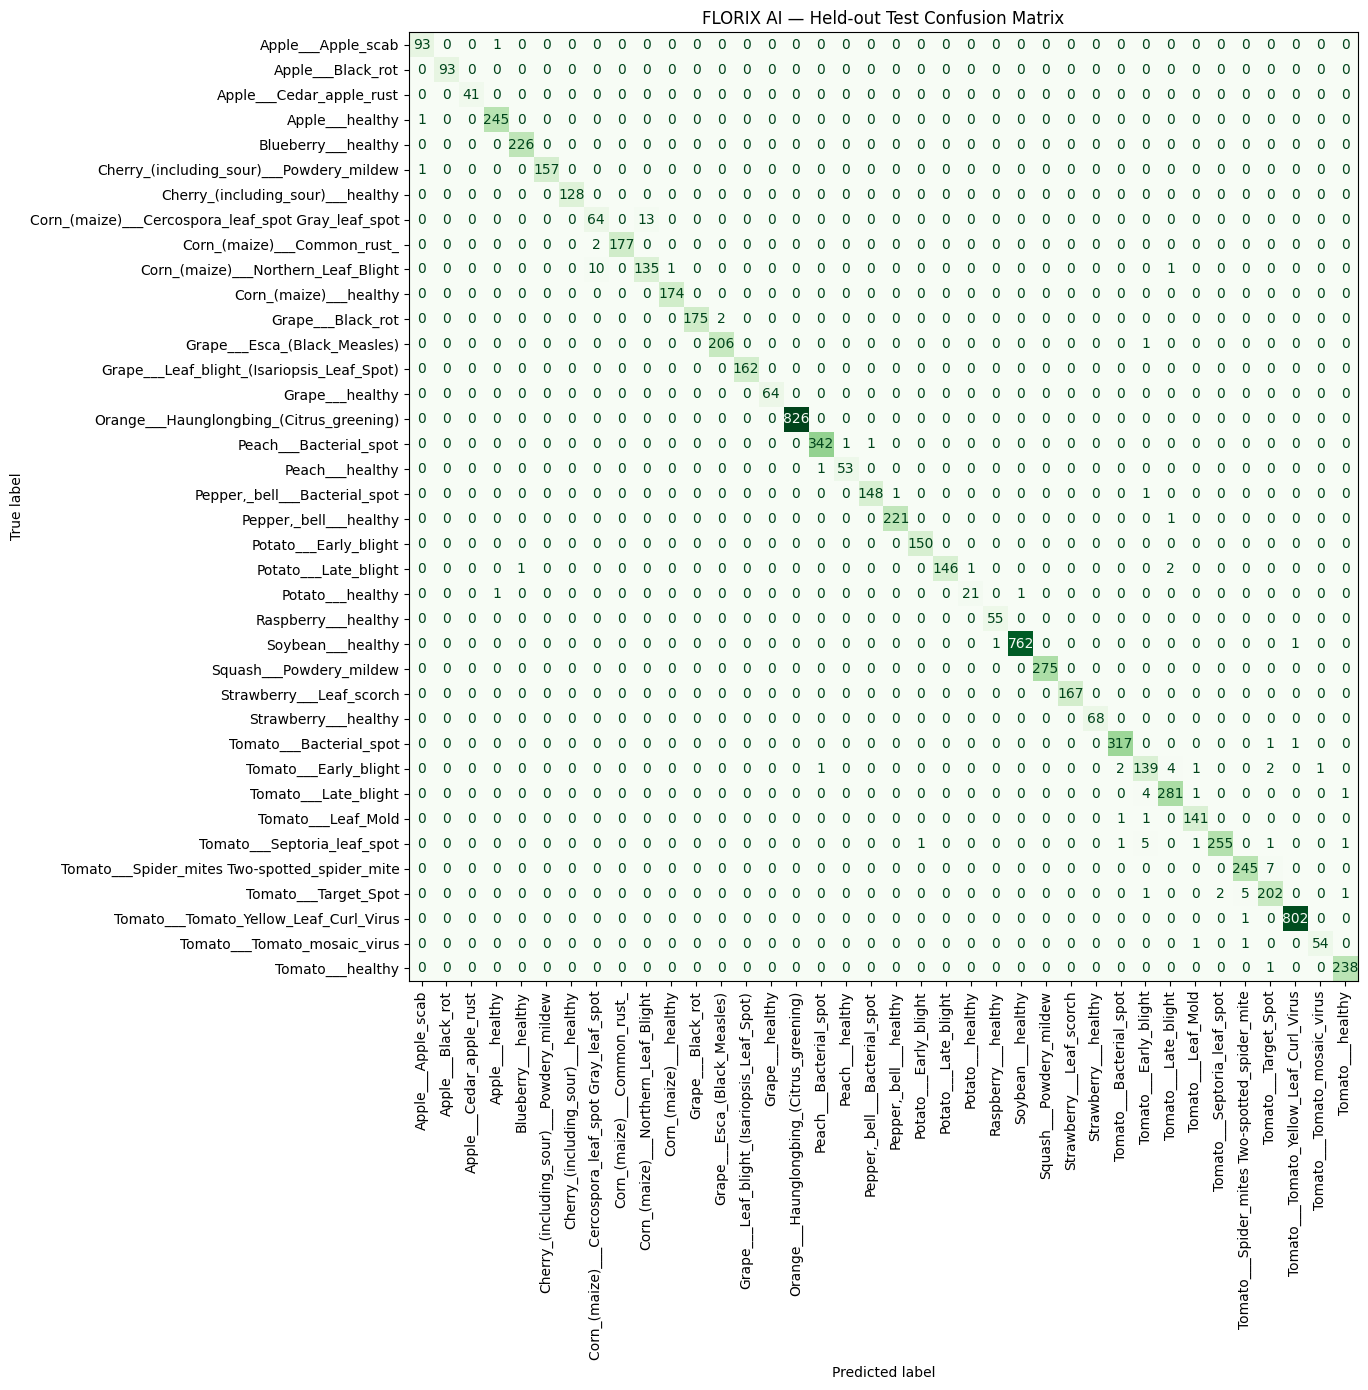

In [13]:
y_true = np.concatenate([y.numpy() for _, y in test_ds])
test_probs = model.predict(test_ds, verbose=1)
y_pred = np.argmax(test_probs, axis=1)
macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
print("Test samples:", len(y_true))
print(f"Accuracy: {accuracy_score(y_true,y_pred)*100:.2f}%")
print(f"Macro precision: {macro_p*100:.2f}% | Macro recall: {macro_r*100:.2f}% | Macro F1: {macro_f1*100:.2f}%")
print(classification_report(y_true, y_pred, labels=list(range(len(class_names))), target_names=class_names, zero_division=0, digits=3))
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(16,14))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=list(range(len(class_names))), display_labels=class_names, xticks_rotation=90, cmap="Greens", colorbar=False, ax=ax)
ax.set_title("FLORIX AI — Held-out Test Confusion Matrix")
plt.tight_layout()
plt.show()


## Cell 8 — Helpers: image quality, uncertainty, severity, plant care

In [9]:
def validate_leaf_image(image):
    if image is None:
        return {"valid":False,"quality":"No image","message":"Upload a leaf image.","warnings":[],"metrics":{}}
    img = image.convert("RGB")
    w,h = img.size
    gray = ImageOps.grayscale(img)
    brightness = float(ImageStat.Stat(gray).mean[0])
    sharpness = float(gray.filter(ImageFilter.FIND_EDGES).getextrema()[1])
    warnings = []
    if min(w,h) < 100: warnings.append("Image resolution is small.")
    if brightness < 35: warnings.append("Image may be too dark.")
    if brightness > 225: warnings.append("Image may be overexposed.")
    if sharpness < 15: warnings.append("Image may be blurry.")
    valid = min(w,h) >= 100 and 20 <= brightness <= 245
    return {"valid":valid,"quality":"Good image quality" if valid and not warnings else "Image needs attention",
            "message":"Image checks passed." if valid else "Use a clearer, well-lit image.",
            "warnings":warnings,"metrics":{"width":w,"height":h,"brightness":round(brightness,2),"sharpness":round(sharpness,2)}}

def analyze_prediction_uncertainty(probabilities):
    p = np.clip(np.asarray(probabilities,dtype=float),1e-12,1)
    order = np.argsort(p)[::-1]
    top, second = float(p[order[0]]), float(p[order[1]])
    margin = top-second
    entropy = float(-np.sum(p*np.log(p))/np.log(len(p)))
    if top < .5 or margin < .15:
        status, recommendation = "Uncertain prediction","Retake the image and seek expert confirmation."
    elif top < .75:
        status, recommendation = "Moderate certainty","Compare alternatives and verify symptoms."
    else:
        status, recommendation = "Model favors one class","Treat this as screening, not a confirmed diagnosis."
    return {"status":status,"top_probability":round(top*100,2),"second_probability":round(second*100,2),
            "margin":round(margin*100,2),"normalized_entropy":round(entropy,4),"recommendation":recommendation}

def estimate_leaf_severity(image):
    arr = np.asarray(image.convert("RGB").resize((IMG_SIZE,IMG_SIZE)),dtype=np.float32)
    r,g,b = arr[...,0],arr[...,1],arr[...,2]
    green = (g > r*.85) & (g > b*.85) & (g > 35)
    discolored = (r > g*1.05) | (b > g*1.08) | (g < 65)
    affected = float(np.sum(discolored & green)/max(np.sum(green),1)*100)
    severity = "Low visible discoloration" if affected < 10 else ("Moderate visible discoloration" if affected < 30 else "High visible discoloration")
    return {"affected_percent":round(affected,2),"severity":severity,"message":"Rough color-based estimate only; lighting and background affect results."}

def get_care_recommendation(predicted_class):
    if "healthy" in predicted_class.lower():
        return {"description":"The model predicts a healthy-class image.","actions":["Continue appropriate watering and normal crop care.","Monitor leaves for new symptoms.","Keep tools clean."]}
    return {"description":"The model predicts a possible disease. Confirm before treatment.","actions":["Inspect several leaves for spreading symptoms.","Avoid unnecessary wetting of foliage and improve airflow where suitable.","Seek local agricultural guidance before applying pesticides."]}


## Cell 9 — Grad-CAM for this EfficientNetB0 architecture

In [10]:
def generate_gradcam(image, model):
    image = image.convert("RGB").resize((IMG_SIZE,IMG_SIZE))
    x = np.asarray(image,dtype=np.float32)[None,...]
    base = next((layer for layer in model.layers if isinstance(layer,tf.keras.Model)),None)
    if base is None:
        raise ValueError("EfficientNet base model not found.")
    conv = base.get_layer("top_conv")
    extractor = tf.keras.Model(base.inputs,conv.output)
    tail, started = [], False
    for layer in base.layers:
        if layer.name == "top_conv":
            started = True
            continue
        if started: tail.append(layer)
    head, after_base = [], False
    for layer in model.layers:
        if layer is base:
            after_base = True
            continue
        if after_base: head.append(layer)
    with tf.GradientTape() as tape:
        features = extractor(x,training=False)
        tape.watch(features)
        z = features
        for layer in tail: z = layer(z,training=False)
        for layer in head: z = layer(z,training=False)
        idx = tf.argmax(z[0])
        score = z[:,idx]
    grads = tape.gradient(score,features)
    if grads is None:
        raise ValueError("Grad-CAM gradients unavailable for this architecture.")
    weights = tf.reduce_mean(grads,axis=(0,1,2))
    heat = tf.maximum(tf.reduce_sum(features[0]*weights,axis=-1),0)
    heat = heat/(tf.reduce_max(heat)+1e-8)
    heat = tf.image.resize(heat[...,None],(IMG_SIZE,IMG_SIZE)).numpy().squeeze()
    colored = (plt.get_cmap("jet")(heat)[...,:3]*255).astype(np.uint8)
    overlay = np.clip(.6*np.asarray(image).astype(np.float32)+.4*colored,0,255).astype(np.uint8)
    return image, heat, overlay


## Cell 10 — PDF report generator

In [11]:
def generate_flora_report(leaf_image,predicted_class,probabilities,class_names,severity_result=None,uncertainty_result=None,gradcam_image=None):
    path = f"/content/FloraGuard_Report_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf"
    doc = SimpleDocTemplate(path,pagesize=letter,rightMargin=40,leftMargin=40,topMargin=40,bottomMargin=40)
    styles = getSampleStyleSheet()
    styles.add(ParagraphStyle(name="FloraTitle",parent=styles["Title"],textColor=colors.HexColor("#087f50")))
    story = [Paragraph("FloraGuard AI — Plant Health Report",styles["FloraTitle"]),
             Paragraph(f"Generated: {datetime.now():%Y-%m-%d %H:%M}",styles["Normal"]),Spacer(1,12)]
    buf = BytesIO()
    leaf_image.convert("RGB").save(buf,format="JPEG"); buf.seek(0)
    story += [PDFImage(buf,width=2.2*inch,height=2.2*inch),Spacer(1,12),
              Paragraph(f"<b>Prediction:</b> {html.escape(str(predicted_class))}",styles["Normal"]),Spacer(1,8)]
    probs = np.asarray(probabilities); order = np.argsort(probs)[::-1][:3]
    data = [["Rank","Class","Score"]] + [[str(i+1),html.escape(str(class_names[int(j)])),f"{probs[j]*100:.2f}%"] for i,j in enumerate(order)]
    table = Table(data,colWidths=[.6*inch,4.5*inch,1*inch])
    table.setStyle(TableStyle([("BACKGROUND",(0,0),(-1,0),colors.HexColor("#087f50")),("TEXTCOLOR",(0,0),(-1,0),colors.white),("GRID",(0,0),(-1,-1),.4,colors.HexColor("#dcebe1")),("PADDING",(0,0),(-1,-1),6)]))
    story += [table,Spacer(1,12)]
    if severity_result:
        story.append(Paragraph(f"<b>Visual estimate:</b> {html.escape(str(severity_result.get('severity')))} ({severity_result.get('affected_percent','N/A')}%)",styles["Normal"]))
        story.append(Paragraph(html.escape(str(severity_result.get("message",""))),styles["BodyText"]))
    if uncertainty_result:
        story.append(Paragraph(f"<b>Uncertainty:</b> {html.escape(str(uncertainty_result.get('status')))}",styles["Normal"]))
        story.append(Paragraph(html.escape(str(uncertainty_result.get("recommendation",""))),styles["BodyText"]))
    if gradcam_image is not None:
        try:
            ob = BytesIO()
            if isinstance(gradcam_image,Image.Image): gradcam_image.convert("RGB").save(ob,format="JPEG")
            else: Image.fromarray(np.asarray(gradcam_image).astype(np.uint8)).save(ob,format="JPEG")
            ob.seek(0); story += [Spacer(1,10),Paragraph("Grad-CAM overlay",styles["Heading2"]),PDFImage(ob,width=2.8*inch,height=2.8*inch)]
        except Exception as exc: print("Grad-CAM omitted from PDF:",exc)
    story += [Spacer(1,12),Paragraph("Disclaimer: This AI output is not a confirmed diagnosis. Confirm disease and treatment with an agricultural expert.",styles["BodyText"])]
    doc.build(story)
    return path


## Cell 11 — One final professional Gradio dashboard

In [17]:

FLORA_LAST_ANALYSIS = None

def flora_analyze_all(image):
    global FLORA_LAST_ANALYSIS
    if image is None:
        FLORA_LAST_ANALYSIS = None
        msg = "<div class='card'>Upload a leaf image to begin.</div>"
        return msg,msg,msg,msg,msg,None
    q = validate_leaf_image(image); m = q["metrics"]
    warnings_html = "".join("<li>"+html.escape(str(w))+"</li>" for w in q["warnings"])
    q_html = f"<div class='card'><div class='eyebrow'>IMAGE QUALITY</div><h3>{html.escape(q['quality'])}</h3><p>{html.escape(q['message'])}</p><p class='muted'>Resolution: {m['width']} × {m['height']} · Brightness: {m['brightness']} · Sharpness: {m['sharpness']}</p><ul>{warnings_html}</ul></div>"
    if not q["valid"]:
        FLORA_LAST_ANALYSIS = None
        msg = "<div class='card'>Please upload a clearer, well-lit leaf image.</div>"
        return q_html,msg,msg,msg,msg,None
    x = np.asarray(image.convert("RGB").resize((IMG_SIZE,IMG_SIZE)),dtype=np.float32)[None,...]
    probs = model.predict(x,verbose=0)[0]; top = np.argsort(probs)[::-1][:3]
    idx = int(top[0]); name = str(class_names[idx]); conf = float(probs[idx])*100
    unc = analyze_prediction_uncertainty(probs); sev = estimate_leaf_severity(image); care = get_care_recommendation(name)
    if conf < 50: status,color,bg,msg = "LOW CONFIDENCE","#b42318","#fff1f0","Retake the image and seek expert confirmation."
    elif conf < 75: status,color,bg,msg = "MODERATE CONFIDENCE","#946200","#fff8e6","Compare alternatives and verify visible symptoms."
    else: status,color,bg,msg = "HIGH MODEL CONFIDENCE","#087f50","#edf8f0","The prediction may still be incorrect; confirm symptoms."
    pred_html = f"<div class='card'><div class='eyebrow'>DISEASE PREDICTION</div><h2>{html.escape(name.replace('___',' — ').replace('_',' '))}</h2><div class='confidence-box'><div class='muted'>Model confidence</div><div class='confidence'>{conf:.2f}%</div><div class='track'><div class='fill' style='width:{conf:.2f}%'></div></div></div><div class='warning' style='color:{color};background:{bg};border-color:{color}55'><b>{status}</b><p>{msg}</p></div><p class='muted'>Confidence is not a guarantee of correctness.</p></div>"
    rows = ""
    for rank,j in enumerate(top,1):
        score=float(probs[j])*100
        rows += f"<div class='rank-row'><span class='rank'>{rank:02}</span><div class='rank-main'><div class='rank-label'><span>{html.escape(str(class_names[int(j)]).replace('___',' — ').replace('_',' '))}</span><b>{score:.2f}%</b></div><div class='track'><div class='fill' style='width:{score:.2f}%'></div></div></div></div>"
    top_html = f"<div class='card'><div class='eyebrow'>ALTERNATIVE PREDICTIONS</div><h3>Top 3 predictions</h3>{rows}</div>"
    diag_html = f"<div class='card'><div class='eyebrow'>ADVANCED DIAGNOSTICS</div><h3>Visible discoloration estimate</h3><div class='confidence'>{sev['affected_percent']}%</div><p>{html.escape(sev['severity'])}</p><p>{html.escape(sev['message'])}</p><hr><h3>Uncertainty</h3><b>{html.escape(unc['status'])}</b><p class='muted'>Top {unc['top_probability']}% · Second {unc['second_probability']}% · Margin {unc['margin']}%</p><p>{html.escape(unc['recommendation'])}</p></div>"
    care_html = f"<div class='card'><div class='eyebrow'>PLANT CARE</div><h3>Recommended next steps</h3><p>{html.escape(care['description'])}</p><ul>{''.join('<li>'+html.escape(str(a))+'</li>' for a in care['actions'])}</ul><p class='muted'>Confirm the disease before treatment.</p></div>"
    gradcam = None
    try:
        _,_,overlay = generate_gradcam(image,model)
        gradcam = Image.fromarray(overlay)
    except Exception as exc:
        print("Grad-CAM unavailable:",exc)
    FLORA_LAST_ANALYSIS = {"image":image.copy(),"predicted_class":name,"probabilities":np.asarray(probs).copy(),"severity":sev,"uncertainty":unc,"gradcam":gradcam}
    return q_html,pred_html,top_html,diag_html,care_html,gradcam

def download_flora_pdf(image):
    global FLORA_LAST_ANALYSIS
    if image is None: raise gr.Error("Upload a leaf image first.")
    FLORA_LAST_ANALYSIS = None
    flora_analyze_all(image)
    if FLORA_LAST_ANALYSIS is None: raise gr.Error("Analysis did not complete. Try a clearer image.")
    r = FLORA_LAST_ANALYSIS
    try:
        return generate_flora_report(r["image"],r["predicted_class"],r["probabilities"],class_names,r["severity"],r["uncertainty"],r["gradcam"])
    except Exception as exc:
        raise gr.Error(f"PDF generation failed: {exc}")

flora_css = """
.gradio-container{max-width:1400px!important;width:100%!important;margin:auto!important;padding:18px!important;background:#f4f8f5!important;font-family:Arial,sans-serif!important}
#hero{padding:26px 30px;margin-bottom:18px;border-radius:16px;background:linear-gradient(120deg,#075b3d,#13a16a);color:white}
#hero h1{color:white!important;font-size:clamp(26px,3vw,38px);margin:10px 0}
#hero p{color:#e5f6eb!important;line-height:1.6}
.card{box-sizing:border-box;width:100%;padding:16px;margin-bottom:12px;border:1px solid #dcebe1;border-radius:13px;background:white}
.card h2{color:#087f50;overflow-wrap:anywhere}.card h3{color:#173b2e;margin:7px 0 10px}
.eyebrow{color:#087f50;font-size:10px;font-weight:800;letter-spacing:1.3px;margin-bottom:8px}
.muted{font-size:12px;color:#6b7e75;line-height:1.6}
.confidence-box{background:#edf7f0;padding:14px;border-radius:10px;margin:12px 0}
.confidence{font-size:28px;font-weight:800;color:#087f50;margin:5px 0 10px}
.track{width:100%;height:7px;background:#e7eee9;border-radius:20px;overflow:hidden}.fill{height:100%;background:linear-gradient(90deg,#43c785,#087f50);border-radius:20px}
.warning{padding:12px;border:1px solid;border-radius:10px;margin:12px 0;font-size:12px;line-height:1.6}.warning p{margin:5px 0 0;color:#52675c}
.rank-row{display:flex;gap:10px;align-items:center;padding:12px 0;border-bottom:1px solid #edf2ee}
.rank{width:36px;height:36px;flex-shrink:0;display:flex;align-items:center;justify-content:center;border-radius:10px;background:#e8f6ed;color:#087f50;font-weight:800}
.rank-main{min-width:0;flex:1}.rank-label{display:flex;justify-content:space-between;gap:8px;font-size:12px;margin-bottom:7px;overflow-wrap:anywhere}.rank-label b{color:#087f50;white-space:nowrap}
#analyze-btn{background:linear-gradient(100deg,#087f50,#13a16a)!important;color:white!important}
#footer{padding:18px;text-align:center;color:#718278;font-size:12px;line-height:1.8}
@media(max-width:760px){.gradio-container{padding:10px!important}#hero{padding:22px 18px}}
"""

with gr.Blocks(title="FLORIX AI | Plant Health",theme=gr.themes.Soft(primary_hue="green",secondary_hue="emerald",neutral_hue="slate"),css=flora_css) as app:
    gr.HTML("<div id='hero'><h1>FLORIX AI 🌿</h1><p>AI-powered plant disease detection with confidence scores, visual explanations, and actionable plant-care recommendations.</p></div>")
    with gr.Row(equal_height=True):
        with gr.Column(scale=4,min_width=280):
            with gr.Group():
                gr.Markdown("### 📸 Plant Scanner")
                image_input=gr.Image(type="pil",label="Upload a clear leaf image",height=280)
                analyze_btn=gr.Button("🌿 Analyze My Plant",variant="primary",elem_id="analyze-btn")
                gr.Markdown("**Tips**\n- Use natural lighting.\n- Keep the leaf in focus.\n- Avoid blurry images.")
        with gr.Column(scale=6,min_width=320):
            gr.Markdown("### 🧠 Plant Health Analysis")
            quality_output=gr.HTML("<div class='card'>Image quality results appear here.</div>")
            prediction_output=gr.HTML("<div class='card'>Prediction results appear here.</div>")
            top_output=gr.HTML("<div class='card'>Top three predictions appear here.</div>")
    with gr.Row(equal_height=True):
        with gr.Column(scale=1,min_width=280):
            gr.Markdown("### 📊 Advanced Diagnostics")
            diagnostics_output=gr.HTML("<div class='card'>Diagnostics appear here.</div>")
        with gr.Column(scale=1,min_width=280):
            gr.Markdown("### 🔬 Explainable AI")
            gradcam_output=gr.Image(label="Grad-CAM overlay",height=280)
    gr.Markdown("### 🌿 Plant-Care Recommendations")
    care_output=gr.HTML("<div class='card'>Recommendations appear here.</div>")
    gr.Markdown("### 📄 Export report")
    with gr.Row():
        pdf_btn=gr.Button("Generate PDF Report",variant="primary")
        pdf_output=gr.File(label="Download report",interactive=False)
    analyze_btn.click(fn=flora_analyze_all,inputs=[image_input],outputs=[quality_output,prediction_output,top_output,diagnostics_output,care_output,gradcam_output])
    pdf_btn.click(fn=download_flora_pdf,inputs=[image_input],outputs=[pdf_output])
    gr.HTML("<div id='footer'><b>FLORIX AI · PLANT HEALTH INTELLIGENCE</b><br>AI predictions and visual estimates are not confirmed diagnoses. Confirm treatment decisions with an agricultural expert.</div>")

app.launch(share=True,inbrowser=True)


/tmp/ipykernel_2481/298509775.py:73: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(title="FLORIX AI | Plant Health",theme=gr.themes.Soft(primary_hue="green",secondary_hue="emerald",neutral_hue="slate"),css=flora_css) as app:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ea530d12e34268c5c4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
